# EuroSAT Land-Cover Classification — A Comparative Deep Learning Study with Transfer Learning

## Notebook 03 — Baseline CNN

## Notebook Goal

Notebook 01 audited the dataset and Notebook 02 built a stratified train/validation/test split and a `tf.data` pipeline. This notebook trains a simple convolutional neural network **from scratch**, using only `train_ds` and `val_ds`, to serve as the project's baseline.

This is not an attempt to get the best possible score. It's a deliberately simple reference point that Notebook 04 (augmentation, BatchNorm, Dropout) and the Transfer Learning notebooks will be compared against. `test_ds` is not touched here — it's reserved for Notebook 08.

## Why a Baseline CNN?

Before trying techniques that are supposed to *improve* results (augmentation, BatchNorm, Dropout, transfer learning), we need a simple, honest number to compare against. Without a baseline, later improvements can't actually be shown to be improvements — there's nothing to improve *from*.

## Imports

In [1]:
from pathlib import Path
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split

## Configuration / Seeds

Same configuration and seed as Notebook 02, so the pipeline below reproduces the exact same split.

In [ ]:
DATASET_ROOT = Path("data/EuroSAT_RGB")

CLASS_NAMES = [
    "AnnualCrop", "Forest", "HerbaceousVegetation",
    "Highway", "Industrial", "Pasture",
    "PermanentCrop", "Residential", "River",
    "SeaLake",
]

CLASS_TO_ID = {class_name: idx for idx, class_name in enumerate(CLASS_NAMES)}
EXPECTED_EXTENSIONS = {".jpg", ".jpeg"}

SEED = 42
IMAGE_SIZE = (64, 64)
NUM_CLASSES = 10
BATCH_SIZE = 32
EPOCHS = 50

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

## Load `train_ds` / `val_ds` (Notebook 02 Pipeline)

This reproduces the exact same manifest, stratified split, and `tf.data` pipeline built in Notebook 02 — same config, same `SEED = 42` — so `train_ds` and `val_ds` here are identical to Notebook 02's. This is not a new split; it's the same one, recreated so this notebook can run on its own.

We deliberately never build a `test_ds` in this notebook at all, so the test set cannot be used here even by accident — it stays reserved for Notebook 08.

In [ ]:
#     Manifest (identical to Notebook 02) 
records = []
for class_name in CLASS_NAMES:
    class_dir = DATASET_ROOT / class_name
    for path in class_dir.iterdir():
        if path.is_file() and path.suffix.lower() in EXPECTED_EXTENSIONS:
            records.append((str(path), class_name, CLASS_TO_ID[class_name]))

manifest_df = pd.DataFrame(records, columns=["filepath", "class_name", "label"])

#  Stratified split (identical two-stage split as Notebook 02) 
train_df, temp_df = train_test_split(
    manifest_df,
    test_size=0.20,
    stratify=manifest_df["label"],
    random_state=SEED,
)
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=SEED,
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print(f"Train:      {len(train_df)}")
print(f"Validation: {len(val_df)}")
print(f"(Test set:  {len(test_df)} — not loaded into a tf.data.Dataset in this notebook)")


#  tf.data pipeline (identical to Notebook 02) 
def load_image(filepath, label):
    #Read a JPEG file, decode it, resize to IMAGE_SIZE, and scale pixels to [0, 1]
    image = tf.io.read_file(filepath)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMAGE_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label


def make_dataset(df, shuffle, seed=SEED, batch_size=BATCH_SIZE):
    filepaths = df["filepath"].values
    labels = df["label"].values

    ds = tf.data.Dataset.from_tensor_slices((filepaths, labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(df), seed=seed, reshuffle_each_iteration=True)

    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds


train_ds = make_dataset(train_df, shuffle=True)
val_ds = make_dataset(val_df, shuffle=False)

print("train_ds:", train_ds)
print("val_ds:  ", val_ds)

Train:      21600
Validation: 2700
(Test set:  2700 — not loaded into a tf.data.Dataset in this notebook)
train_ds: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 64, 64, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>
val_ds:   <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 64, 64, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>


## Build Baseline CNN

The architecture is a simple stack of three Conv2D + MaxPooling2D blocks, then a dense classifier:

- **Conv2D** — learns spatial patterns such as edges, textures, and shapes, via small learned filters.
- **MaxPooling2D** — shrinks the spatial dimensions while keeping the strongest local features, which reduces computation and adds some translation tolerance.
- **Flatten** — turns the final 2D feature maps into a single 1D vector so a Dense layer can use them.
- **Dense** — combines the learned features to make the actual classification decision.
- **Softmax** — turns the final 10 raw scores into a probability distribution over the 10 EuroSAT classes.

No BatchNormalization, Dropout, or augmentation yet — those are Notebook 04's experiments. This model is meant to stay recognizably simple.

In [4]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(64, 64, 3)),

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(NUM_CLASSES, activation="softmax"),
], name="baseline_cnn")

## Model Summary

In [5]:
model.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 684,490 (2.61 MB)

 Trainable params: 684,490 (2.61 MB)

 Non-trainable params: 0 (0.00 B)

**Trainable parameters** are the weights and biases the model actually updates during training (through backpropagation). The summary above shows how many of these exist per layer and in total — this number is also used later to compare model sizes against the improved CNN and the pretrained architectures.

## Compile Model

Labels here are plain integer class IDs (0–9), not one-hot vectors, so `sparse_categorical_crossentropy` is the right loss — it compares the model's predicted class probabilities directly against an integer label, without requiring us to one-hot encode anything first.

In [6]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

## Train Model

Trained for up to `EPOCHS = 50`, with a simple `EarlyStopping` callback that monitors validation loss, stops if it hasn't improved for 5 epochs, and restores the best weights seen — this avoids babysitting the epoch count by hand without adding real complexity. In the recorded run, `EarlyStopping` ended training after epoch 15 (best-loss epoch 10 + patience 5), so only 15 of the 50 allowed epochs were used.

In [7]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping],
)

Epoch 1/50


...\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


675/675 ━━━━━━━━━━━━━━━━━━━━ 22s 30ms/step - accuracy: 0.5450 - loss: 1.1726 - val_accuracy: 0.6856 - val_loss: 0.8421
Epoch 2/50
675/675 ━━━━━━━━━━━━━━━━━━━━ 26s 39ms/step - accuracy: 0.7335 - loss: 0.7378 - val_accuracy: 0.7593 - val_loss: 0.6649
Epoch 3/50
675/675 ━━━━━━━━━━━━━━━━━━━━ 26s 38ms/step - accuracy: 0.7756 - loss: 0.6248 - val_accuracy: 0.7619 - val_loss: 0.6529
Epoch 4/50
675/675 ━━━━━━━━━━━━━━━━━━━━ 26s 39ms/step - accuracy: 0.8019 - loss: 0.5478 - val_accuracy: 0.8104 - val_loss: 0.5199
Epoch 5/50
675/675 ━━━━━━━━━━━━━━━━━━━━ 26s 39ms/step - accuracy: 0.8278 - loss: 0.4793 - val_accuracy: 0.8070 - val_loss: 0.5465
Epoch 6/50
675/675 ━━━━━━━━━━━━━━━━━━━━ 27s 39ms/step - accuracy: 0.8471 - loss: 0.4220 - val_accuracy: 0.8367 - val_loss: 0.4419
Epoch 7/50
675/675 ━━━━━━━━━━━━━━━━━━━━ 26s 38ms/step - accuracy: 0.8609 - loss: 0.3882 - val_accuracy: 0.8126 - val_loss: 0.5377
Epoch 8/50
675/675 ━━━━━━━━━━━━━━━━━━━━ 26s 38ms/step - accuracy: 0.8826 - loss: 0.3321 - val_accurac

## Training History

In [8]:
history_df = pd.DataFrame(history.history)
history_df.index = history_df.index + 1
history_df.index.name = "epoch"

history_df

,accuracy,loss,val_accuracy,val_loss
epoch,,,,
1,0.544954,1.172604,0.685556,0.842109
2,0.733519,0.737821,0.759259,0.664931
3,0.775602,0.624803,0.761852,0.652899
4,0.801898,0.547807,0.810370,0.519881
5,0.827824,0.479316,0.807037,0.546504
6,0.847083,0.422014,0.836667,0.441914
7,0.860880,0.388221,0.812593,0.537687
8,0.882593,0.332093,0.854815,0.416299
9,0.896759,0.291451,0.861481,0.410334


## Accuracy Plot

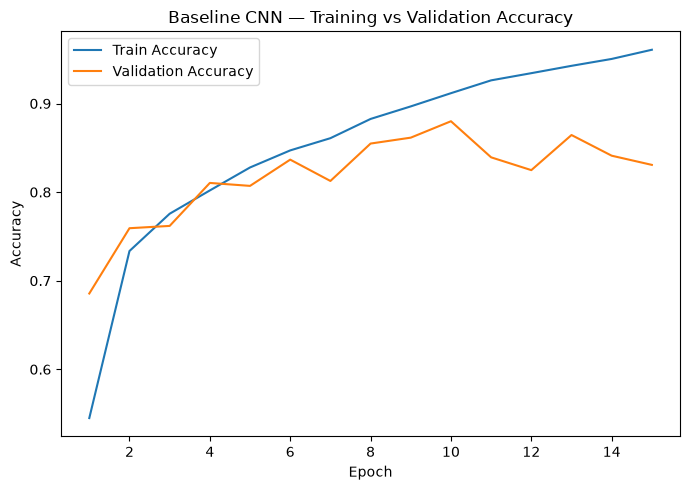

In [9]:
plt.figure(figsize=(7, 5))
plt.plot(history_df.index, history_df["accuracy"], label="Train Accuracy")
plt.plot(history_df.index, history_df["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Baseline CNN — Training vs Validation Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

## Loss Plot

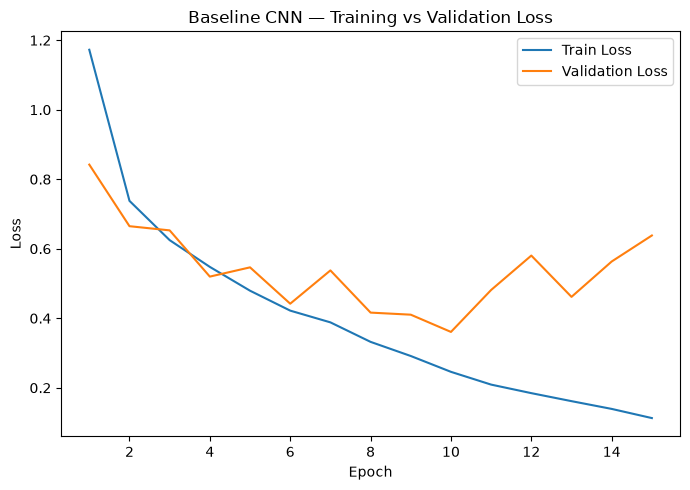

In [10]:
plt.figure(figsize=(7, 5))
plt.plot(history_df.index, history_df["loss"], label="Train Loss")
plt.plot(history_df.index, history_df["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Baseline CNN — Training vs Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()

## Best Validation Results

The epoch with the lowest validation loss and the epoch with the highest validation accuracy aren't always the same — both are reported separately.

In [11]:
best_val_loss_epoch = int(history_df["val_loss"].idxmin())
best_val_loss = history_df.loc[best_val_loss_epoch, "val_loss"]

best_val_acc_epoch = int(history_df["val_accuracy"].idxmax())
best_val_acc = history_df.loc[best_val_acc_epoch, "val_accuracy"]

print("Best validation loss:")
print(f"  Epoch {best_val_loss_epoch}")
print(f"  Validation loss: {best_val_loss:.4f}")

print("\nBest validation accuracy:")
print(f"  Epoch {best_val_acc_epoch}")
print(f"  Validation accuracy: {best_val_acc:.2%}")

Best validation loss:
  Epoch 10
  Validation loss: 0.3607

Best validation accuracy:
  Epoch 10
  Validation accuracy: 88.00%


## Baseline Results Summary

In [12]:
total_params = model.count_params()

results_summary_df = pd.DataFrame(
    [
        ["Best Validation Accuracy", f"{best_val_acc:.2%}"],
        ["Best Validation Loss", f"{best_val_loss:.4f}"],
        ["Epoch of Best Validation Accuracy", best_val_acc_epoch],
        ["Epoch of Best Validation Loss", best_val_loss_epoch],
        ["Total Parameters", f"{total_params:,}"],
    ],
    columns=["Metric", "Result"],
)

results_summary_df

,Metric,Result
0,Best Validation Accuracy,88.00%
1,Best Validation Loss,0.3607
2,Epoch of Best Validation Accuracy,10
3,Epoch of Best Validation Loss,10
4,Total Parameters,"684,490"


## Training Behavior Discussion

Training accuracy rose steadily from 54.50% (Epoch 1) to 96.07% (Epoch 15), and training loss fell from 1.1726 to 0.1128. Validation performance improved over the first 10 epochs, though not smoothly (for example, validation accuracy dipped from 83.67% at Epoch 6 to 81.26% at Epoch 7, and validation loss rose from 0.4419 to 0.5377 over the same step). It reached its best values at **Epoch 10**: 88.00% validation accuracy and 0.3607 validation loss.

After Epoch 10 the two curves diverged. Training accuracy kept rising, while validation loss rose over the remaining epochs (0.4814, 0.5804, 0.4616, 0.5633, 0.6382 at Epochs 11-15) and validation accuracy fell back to between 82.48% and 86.44% (83.07% at Epoch 15). By Epoch 15 the gap between training and validation accuracy was 13.00 points (96.07% vs 83.07%). Validation loss rising while training loss keeps falling is the typical overfitting pattern, so this run shows **reasonable learning up to about Epoch 10 and overfitting after it**; it does not look like underfitting.

`EarlyStopping` stopped the run after Epoch 15 (best-loss Epoch 10 + patience 5) and restored the Epoch 10 weights. For this model the best-accuracy epoch and best-loss epoch coincide (Epoch 10).


## Baseline Purpose

> This model is intentionally simple. It serves as the reference point for later experiments. Notebook 04 will investigate whether augmentation, BatchNormalization, and Dropout can improve generalization compared with this baseline.

## Key Takeaways

- The baseline is a 3-block CNN with 684,490 trainable parameters, trained from scratch on `train_ds` only, with validation on `val_ds`. The test set was not used.
- **Best validation accuracy: 88.00% at Epoch 10. Best validation loss: 0.3607 at Epoch 10.** Both occur at the same epoch.
- Up to Epoch 10 the model learned reasonably well. After that, validation loss rose (to 0.6382 at Epoch 15) while training accuracy continued to climb (96.07%), a 13-point train/validation gap, which indicates overfitting.
- `EarlyStopping` (monitoring `val_loss`, patience 5) stopped training at Epoch 15 out of a maximum of 50 and restored the Epoch 10 weights.
- This is a single run, so it serves as a simple reference point rather than a precise benchmark. Notebook 04 compares controlled changes against it, and Notebooks 05-07 compare transfer learning against it.
